## Module 3: Computational Drug Discovery Project Template

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Obesity is a chronic medical condition where excess body fat builds up in the body that can negatively impact health, quality of life, and longevity.

- Prevalence and Incidence: Around 1.1 billion people in the world live with obesity, with roughly 16% of adults aged 18 and older affected as of 2024. At the same time, 170 million children/adolescents aged 5-19 were living with obesity, as well as 35 million children under age 5. Rapid obesity spikes occur in low- and middle-income countries, with rates of 32% in South-East Asia and Africa to 68% in the Americas. Specifically in the U.S., 40.3% of adults have obesity, with 9.4% having severe obesity. 
https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight

- Symptoms/Diagnosis: Obesity does not have a direct symptom, but carrying excess body fat creates physical strain and metabolic issues that often show in day to day living and in secondary health conditions. Some physical signs include: excess body fat accumulation, shortness of breath, joint and back pain, persistent fatigue, excessive sweating, and rashes/infections on the skin. Excess tissue around the neck can constrict airways during sleep, causing loud snoring or obstructive sleep apnea. Obesity is diagnosed through physical measurements like a Body Mass Index (BMI) of 30 or higher and high waist measurements. BMI can't distinguish muscle from fat, so waist circumference and waist-to-height/hip ratio are used to confirm excess body fat. Once excess body fat is confirmed, doctors evaluate whether it actually impairs health or not and classifies the obesity into two categories: preclinical obesity (excess body fat with regular organ function and normal daily mobility), and clinical obesity (heart failure, sleep apnea, metabolic syndrome).
https://www.mayoclinic.org/diseases-conditions/obesity/symptoms-causes/syc-20375742
https://www.thelancet.com/pb-assets/Lancet/infographics/clinical-obesity/Clinical_Obesity_-_text-only-1736175269007.pdf

- Standard of care treatments (& reimbursement): obesity is regularly treated as a chronic, progressive disease that varies from individual to individual. Treatment includes behavioral & lifestyle therapy---targeting calorie deficit, increased physical activity, self-monitoring, and structured behavior changes. In addition, individuals with a BMI of over 30/27 kg/m^2 are offered pharmacotherapy, with medication changing overtime as well as nutritional/protein monitoring to prevent weight regain. In extreme cases, metabolic and bariatric surgery are recommended to patients with severe obesity or when lifestyle changes/pharmacotherapy do not result in sufficient health outcomes. Anti-obesity medications and bariatric surgery coverage varies by employer plan and state Medicaid policy, but traditional Part D plans have exclusions for drugs for weight loss.
https://pmc.ncbi.nlm.nih.gov/articles/PMC4486408/

- Disease progression & prognosis: Excess body fat (specifically visceral and ectopic fat) triggers chronic inflammation, insulin resistance, and hormonal shifts. Over time, the body adapts to a higher weight threshold, making weight gain progressive and weight loss difficut to sustain without continuous care. There are two categories: preclinical obesity (Stage 1) and clinical obesity (Stages 2-3). Through preclinical obesity does not affect organs or daily function, individuals carry a high risk of progressing to clinical obesity. Excess amounts of body fat causes tissue/organ dysfunction, physical limitations, or obesity-related complications/diseases. Without intervention, childhood/adolescnet obesity often lasts until adulthood. The peak BMI reached and the total number of years lived with excess weight show a direct relationship with long-term health risks.
Untreated obesity can lead to type 2 diabeties, hypertension, dyslipidemia, cornorary artery disease, or heart failure, as well as metabolic dysfunction-associated steatotic liver disease which can progress to steatohepatitis. It also has an increased risk for at least 13 types of cancer, infertility, and pregnancy complications. Additionally, because biological appetite and metabolic adaptations continue after weight loss, stopping treatment commonly leads to weight regain.  Long-term prognosis is best when obesity is managed continuously like hypertension or diabetes.
https://pmc.ncbi.nlm.nih.gov/articles/PMC11870235/
https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight

- Biological mechanisms: Obesity develops through a complex neuroendocrine, metabolic, and inflammatory network that changes energy balance and defends higher body fat storage. In the brain, the hypothalamus uses hormonal signals to control appetite, but chronic overnutrition leads to leptin resistance, where the brain becomes unresponsive to cues from excess fat to be satisfied, and instead craves calorie-dense foods. At the same time, gut-brain signaling is altered by elevated hunger hormones like ghrelin and post-meal satiety hormones such as GLP-1, PYY, and amylin. As fat cells grow larger beyond their healthy capacity, they trigger chronic inflammation and spill excess lipids into vital organs like the liver and pancrease, driving insulin resistance. Finally, metabolic adaptation and genetic susceptibility lower resting energy and heighten hunger during weight loss, creating a biological push towards weight regain.
https://pmc.ncbi.nlm.nih.gov/articles/PMC10843116/

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

**Task 1 Code**

Fitted Kd2 (cavalitide) = 0.077 nM


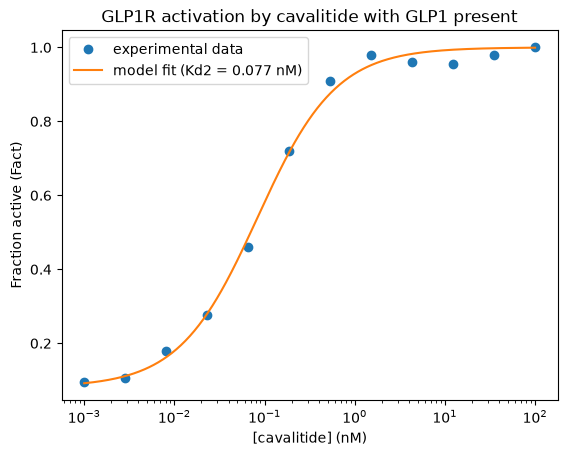

In [2]:
# Task 1: adapted from fit_semaglutide_GLP1R.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17    # L1, GLP1
L1 = 0.015    # [nM] GLP1 (fasting)

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Fit Kd2 (cavalitide) with curve_fit
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
print(f"Fitted Kd2 (cavalitide) = {Kd2_fit:.3f} nM")

L2 = np.logspace(-3, 2, 500)  # [nM] cavalitide
plt.semilogx(L2_loaded, Fact_loaded, "o", label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), label=f"model fit (Kd2 = {Kd2_fit:.3f} nM)")
plt.xlabel("[cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by cavalitide with GLP1 present")
plt.legend()
plt.show()

**b)** The model curve goes through the data points above it seems to be a good fit.

**c) Fitted Kd for Cavalitide = 0.077 nM** (semaglutide: 0.38 nM). Cavalitide's Kd is about 5 times smaller, so it binds the GLP1 receptor about 5 times more tightly and activates the same fraction of receptors at about 5 times lower concentration.
- **Advantages:** less drug is needed for the same effect, which matters for a pill because only about 1% of an oral dose is absorbed (less drug per pill, lower cost). It also binds more tightly than natural GLP1 (Kd = 0.17 nM).
- **Disadvantages:** receptors become fully activated at low concentrations, so it is easier to over-activate them (more side effects such as nausea), and small dosing errors have a bigger effect.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

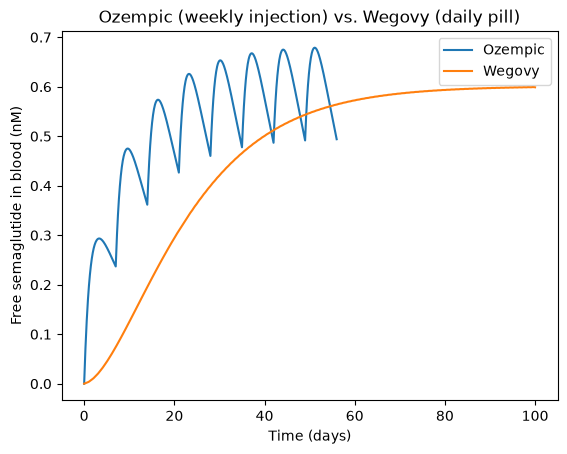

In [3]:
# Task 2.1: semaglutidePK.py with solve_ivp instead of Euler's method
from scipy.integrate import solve_ivp

# product-specific parameters (from semaglutidePK.py)
products = {
    'Ozempic': dict(Favailable=0.89, ka=0.029, D=2.0, interval=168, n_doses=8),   # weekly injection
    'Wegovy':  dict(Favailable=0.01, ka=0.0029, D=25, interval=24, n_doses=100),  # daily pill
}

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

def ODEfunc(t, y, ka):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(p):
    """Repeated dosing with solve_ivp; returns time (h) and blood concentration (nM)."""
    t_out, Cc_out = [], []
    y = [0.0, 0.0]
    for i in range(p['n_doses']):
        y[0] += p['Favailable']*p['D']        # absorbed fraction of dose enters the depot
        t0 = i * p['interval']
        sol = solve_ivp(ODEfunc, (t0, t0 + p['interval']), y, args=(p['ka'],),
                        t_eval=np.linspace(t0, t0 + p['interval'], 100))
        t_out.append(sol.t)
        Cc_out.append(sol.y[1])
        y = list(sol.y[:, -1])                # carry state into next interval
    t = np.concatenate(t_out)
    Cc_nM = np.concatenate(Cc_out) * 1e-3 / MW * 1e9   # mg/L -> nM
    return t, Cc_nM

for drug in ['Ozempic', 'Wegovy']:
    t, Cc = simulate(products[drug])
    plt.plot(t/24, Ffree*Cc, label=drug)
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide in blood (nM)")
plt.title("Ozempic (weekly injection) vs. Wegovy (daily pill)")
plt.legend()
plt.show()


**1)** Both drugs level off at about the same free blood concentration (about 0.6 nM), but the profiles are different. Ozempic (weekly injection, fast absorption) rises quickly and goes up and down every week. Wegovy (daily pill, slow absorption) rises slowly and smoothly and takes about 2 months to level off.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*